# **Understanding Conditions & Data**

1) How changes in temperature, soil moisture, rainfall, evaporation, and vegetation stress relate to crop vulnerability and soil health?

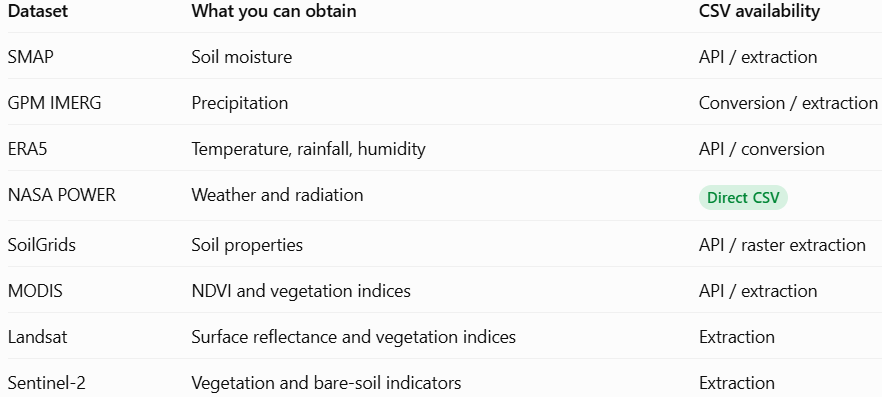

In [3]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
import os

In [9]:
# This file contains the information regarding agriculture
agriculture_df = pd.read_csv("agriculture_dataset.csv") # Our dataset
agriculture_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Farm_ID                    50 non-null     object 
 1   Crop_Type                  50 non-null     object 
 2   Farm_Area(acres)           50 non-null     float64
 3   Irrigation_Type            50 non-null     object 
 4   Fertilizer_Used(tons)      50 non-null     float64
 5   Pesticide_Used(kg)         50 non-null     float64
 6   Yield(tons)                50 non-null     float64
 7   Soil_Type                  50 non-null     object 
 8   Season                     50 non-null     object 
 9   Water_Usage(cubic meters)  50 non-null     float64
dtypes: float64(5), object(5)
memory usage: 4.0+ KB


2) Explanation of scientific terms such as evapotranspiration, soil moisture anomalies, vegetation indices (e.g., NDVI), frost risk, and water‑balance indicators.

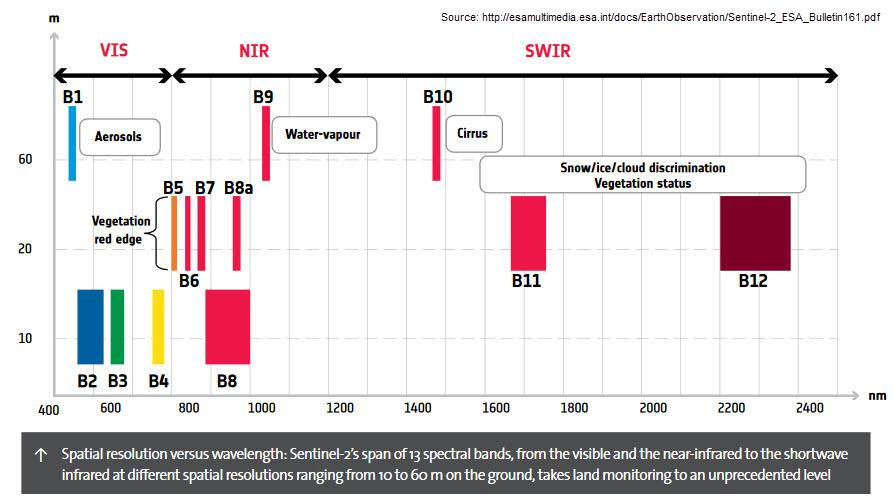

Vegetation absorbs much of the red light for photosynthesis and reflects a large amount of near-infrared radiation.

The Normalized Difference Vegetation Index (NDVI) is a simple remote-sensing metric used to measure and monitor the health, density, and growth of plant cover.

NDVI uses this difference: NDVI=NIR-RED/(NIR+RED)


For Sentinel-2: NDVI=B8-B4/(B8+B4)

Why Sentinel-2 and why not just MODIS?
The choice depends on what you want to predict.

If your goal is global historical environmental patterns, MODIS is convenient.

If your goal is predicting yield for individual agricultural fields, Sentinel-2 is usually more suitable because of its finer spatial resolution.




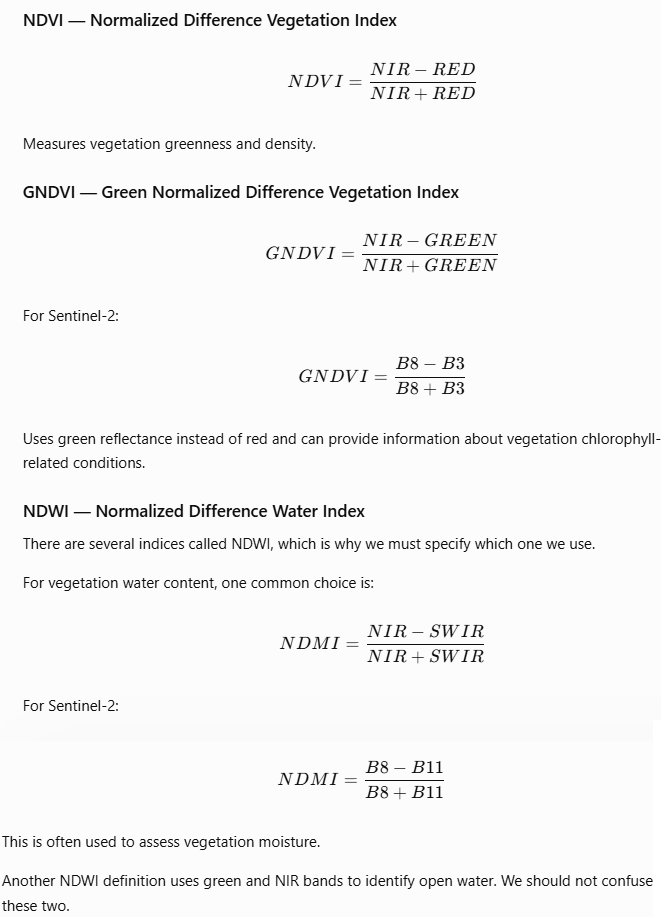

# **SI, Modeling, and Data Fusion**

1) Identification of patterns in historical climate and soil conditions.

Consider how SI could highlight seasonal transitions, bare‑field periods, or times when current crops show increased stress.
Explain how the model interprets uncertainty and where local expertise would be needed to validate results.
You may consider harmonizing datasets with different spatial and temporal resolutions by downsampling, aggregating, or resampling them to a common analysis grid. Harmonizing resolution can help the SI combine SMAP soil moisture, ECOSTRESS land‑surface temperature, GPM precipitation, Landsat/MODIS vegetation indices, GEDI biomass, and soil datasets into coherent features that support clear, explainable rotation‑strategy comparisons.

In [7]:
!pip -q install \
    pandas \
    numpy \
    requests \
    geopandas \
    rasterio \
    xarray \
    netCDF4 \
    earthengine-api \
    geemap \
    tqdm

In [35]:
from pathlib import Path

# ==============================
# PROJECT CONFIGURATION
# ==============================

PROJECT_NAME = "Global_Agricultural_SI"

# Number of agricultural locations
NUMBER_OF_LOCATIONS = 100

# Maximum locations sampled per country
MAX_PER_COUNTRY = 20

# Historical period
START_DATE = "2020-01-01"
END_DATE = "2025-12-31"

# Project directories
ROOT = Path(PROJECT_NAME)

DIRECTORIES = [
    "data/raw/locations",
    "data/raw/nasa_power",
    "data/raw/soilgrids",
    "data/raw/smap",
    "data/raw/gpm",
    "data/raw/modis",
    "data/raw/era5",
    "data/processed",
    "data/final",
    "logs"
]

for directory in DIRECTORIES:
    (ROOT / directory).mkdir(
        parents=True,
        exist_ok=True
    )

print("Project initialized!")
print("Root directory:", ROOT)

Project initialized!
Root directory: Global_Agricultural_SI


In [36]:
import ee

ee.Authenticate()

# Replace with your own registered Google Cloud project ID
ee.Initialize(project="nasahack-514813")

print("Earth Engine connected!")

Earth Engine connected!


In [37]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [38]:
import os

# Check that Google Drive is mounted
print(os.path.exists('/content/drive/MyDrive'))

# Search for the exported CSV
for root, dirs, files in os.walk('/content/drive/MyDrive'):

    for file in files:

        if "cropland_candidates" in file.lower():

            print("FOUND!")
            print(os.path.join(root, file))

True
FOUND!
/content/drive/MyDrive/Agricultural_SI/cropland_candidates.csv


In [39]:
import os
import pandas as pd

file_path = None

for root, dirs, files in os.walk('/content/drive/MyDrive'):

    for file in files:

        if file.lower() == "cropland_candidates.csv":

            file_path = os.path.join(root, file)
            break

    if file_path:
        break

if file_path is None:
    raise FileNotFoundError(
        "CSV not found. Check your Google Drive export folder."
    )

points = pd.read_csv(file_path)

print("CSV successfully loaded!")
print("File:", file_path)
print("Rows:", len(points))

display(points.head())

CSV successfully loaded!
File: /content/drive/MyDrive/Agricultural_SI/cropland_candidates.csv
Rows: 33000


,.geo
0,"{""geodesic"":false,""type"":""Point"",""coordinates""..."
1,"{""geodesic"":false,""type"":""Point"",""coordinates""..."
2,"{""geodesic"":false,""type"":""Point"",""coordinates""..."
3,"{""geodesic"":false,""type"":""Point"",""coordinates""..."
4,"{""geodesic"":false,""type"":""Point"",""coordinates""..."


In [40]:
def extract_coordinates(value):

    if pd.isna(value):
        return None, None

    geometry = json.loads(value)

    lon, lat = geometry["coordinates"]

    return lat, lon

In [41]:
print(points.columns.tolist())
print(points.shape)

['.geo']
(33000, 1)


In [42]:
import pandas as pd
import geopandas as gpd
import json

# ==========================================
# 1. READ EXPORTED CANDIDATES
# ==========================================

points = pd.read_csv(
    "/content/drive/MyDrive/Agricultural_SI/cropland_candidates.csv"
)

# Extract coordinates from Earth Engine geometry
def extract_coordinates(value):

    if pd.isna(value):
        return None, None

    geometry = json.loads(value)

    lon, lat = geometry["coordinates"]

    return lat, lon


coordinates = points[".geo"].apply(
    extract_coordinates
)

points["latitude"] = coordinates.apply(
    lambda x: x[0]
)

points["longitude"] = coordinates.apply(
    lambda x: x[1]
)

points = points.dropna(
    subset=["latitude", "longitude"]
)

# ==========================================
# 2. LOAD COUNTRY BOUNDARIES
# ==========================================

countries = gpd.read_file(
    "https://naturalearth.s3.amazonaws.com/"
    "110m_cultural/ne_110m_admin_0_countries.zip"
)

geo_points = gpd.GeoDataFrame(
    points,
    geometry=gpd.points_from_xy(
        points["longitude"],
        points["latitude"]
    ),
    crs="EPSG:4326"
)

# ==========================================
# 3. IDENTIFY COUNTRIES
# ==========================================

joined = gpd.sjoin(
    geo_points,
    countries[["ADMIN", "geometry"]],
    how="inner",
    predicate="within"
)

joined = joined.rename(
    columns={"ADMIN": "country"}
)

# ==========================================
# 4. SELECT LOCATIONS
# ==========================================

joined = joined.drop_duplicates(
    subset=["latitude", "longitude"]
)

selected = (
    joined.groupby("country", group_keys=False)
    .apply(
        lambda group: group.sample(
            n=min(len(group), MAX_PER_COUNTRY),
            random_state=42
        )
    )
    .reset_index(drop=True)
)

selected = selected.sample(
    n=min(NUMBER_OF_LOCATIONS, len(selected)),
    random_state=42
).reset_index(drop=True)

# ==========================================
# 5. CREATE FINAL DATASET
# ==========================================

selected["location_id"] = [
    f"field_{i:04d}"
    for i in range(1, len(selected) + 1)
]

selected["field_name"] = [
    f"Cropland_{i:04d}"
    for i in range(1, len(selected) + 1)
]

locations = selected[
    [
        "location_id",
        "latitude",
        "longitude",
        "country",
        "field_name"
    ]
]

locations.to_csv(
    "/content/locations.csv",
    index=False
)

print("LOCATION GENERATION COMPLETE!")
print("Total locations:", len(locations))
print("Countries:", locations["country"].nunique())

display(locations.head(10))

print("\nCountry distribution:")
display(locations["country"].value_counts())


LOCATION GENERATION COMPLETE!
Total locations: 100
Countries: 71


/tmp/ipykernel_727/1567211630.py:85: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


,location_id,latitude,longitude,country,field_name
0,field_0001,13.100466,-87.253438,Honduras,Cropland_0001
1,field_0002,35.576315,59.459414,Iran,Cropland_0002
2,field_0003,36.744124,-116.996658,United States of America,Cropland_0003
3,field_0004,12.004522,-16.286531,Guinea-Bissau,Cropland_0004
4,field_0005,-37.133324,-66.655069,Argentina,Cropland_0005
5,field_0006,35.504449,139.391508,Japan,Cropland_0006
6,field_0007,-18.708878,-66.708968,Bolivia,Cropland_0007
7,field_0008,5.716315,-59.261934,Guyana,Cropland_0008
8,field_0009,7.539895,-12.468691,Sierra Leone,Cropland_0009
9,field_0010,28.524540,83.965455,Nepal,Cropland_0010



Country distribution:


,count
country,
Honduras,3
Japan,3
Czechia,3
Canada,3
Mongolia,3
...,...
North Korea,1
Switzerland,1
Netherlands,1


# NASA POWER — global weather extraction

In [43]:
import requests
import pandas as pd
import time
from tqdm.auto import tqdm

POWER_URL = (
    "https://power.larc.nasa.gov/"
    "api/temporal/daily/point"
)

POWER_PARAMETERS = [
    "T2M",
    "T2M_MAX",
    "T2M_MIN",
    "PRECTOTCORR",
    "RH2M",
    "ALLSKY_SFC_SW_DWN"
]

def download_nasa_power(location): # Download daily weather for all locations

    params = {
        "parameters": ",".join(POWER_PARAMETERS),
        "community": "AG",
        "longitude": float(location["longitude"]),
        "latitude": float(location["latitude"]),
        "start": START_DATE.replace("-", ""),
        "end": END_DATE.replace("-", ""),
        "format": "JSON",
        "time-standard": "UTC"
    }

    response = requests.get(
        POWER_URL,
        params=params,
        timeout=180
    )

    response.raise_for_status()

    data = response.json()

    measurements = data["properties"]["parameter"]

    df = pd.DataFrame(measurements)

    df.index = pd.to_datetime(
        df.index,
        format="%Y%m%d"
    )

    df.index.name = "date"

    df = df.reset_index()

    # NASA missing-value marker
    df = df.replace(-999, pd.NA)

    # Add location metadata
    for column in [
        "location_id",
        "latitude",
        "longitude",
        "country",
        "field_name"
    ]:
        df[column] = location[column]

    return df


# --------------------------------
# RUN DOWNLOADS
# --------------------------------

power_results = []
power_errors = []

for _, location in tqdm(
    locations.iterrows(),
    total=len(locations)
):

    try:

        df = download_nasa_power(location)

        power_results.append(df)

        df.to_csv(
            ROOT / "data/raw/nasa_power" /
            f"{location['location_id']}.csv",
            index=False
        )

    except Exception as error:

        power_errors.append({
            "location_id": location["location_id"],
            "error": str(error)
        })

    time.sleep(1)


if power_results:

    power_data = pd.concat(
        power_results,
        ignore_index=True
    )

    power_data.to_csv(
        ROOT / "data/processed/weather.csv",
        index=False
    )

    print("Weather extraction completed!")
    print(power_data.head())

else:
    power_data = pd.DataFrame()
    print("No weather data downloaded.")

pd.DataFrame(power_errors).to_csv(
    ROOT / "logs/nasa_power_errors.csv",
    index=False
)

  0%|          | 0/100 [00:00<?, ?it/s]

Weather extraction completed!
        date    T2M  T2M_MAX  T2M_MIN  PRECTOTCORR   RH2M  ALLSKY_SFC_SW_DWN  \
0 2020-01-01  28.60    31.86    25.13         0.01  62.79              19.44   
1 2020-01-02  28.98    33.00    25.90         0.12  61.47              20.53   
2 2020-01-03  28.76    32.32    25.99         0.01  64.03              20.15   
3 2020-01-04  28.99    33.78    26.25         0.02  66.39              18.84   
4 2020-01-05  30.03    34.18    26.25         0.00  57.85              20.23   

  location_id   latitude  longitude   country     field_name  
0  field_0001  13.100466 -87.253438  Honduras  Cropland_0001  
1  field_0001  13.100466 -87.253438  Honduras  Cropland_0001  
2  field_0001  13.100466 -87.253438  Honduras  Cropland_0001  
3  field_0001  13.100466 -87.253438  Honduras  Cropland_0001  
4  field_0001  13.100466 -87.253438  Honduras  Cropland_0001  


# MODIS — vegetation indices

In [44]:
features = []

for _, row in locations.iterrows():

    feature = ee.Feature(
        ee.Geometry.Point([
            float(row["longitude"]),
            float(row["latitude"])
        ]),
        {
            "location_id": row["location_id"],
            "country": row["country"],
            "latitude": float(row["latitude"]),
            "longitude": float(row["longitude"])
        }
    )

    features.append(feature)

ee_points = ee.FeatureCollection(features)

print("Earth Engine locations:", len(features))

Earth Engine locations: 100


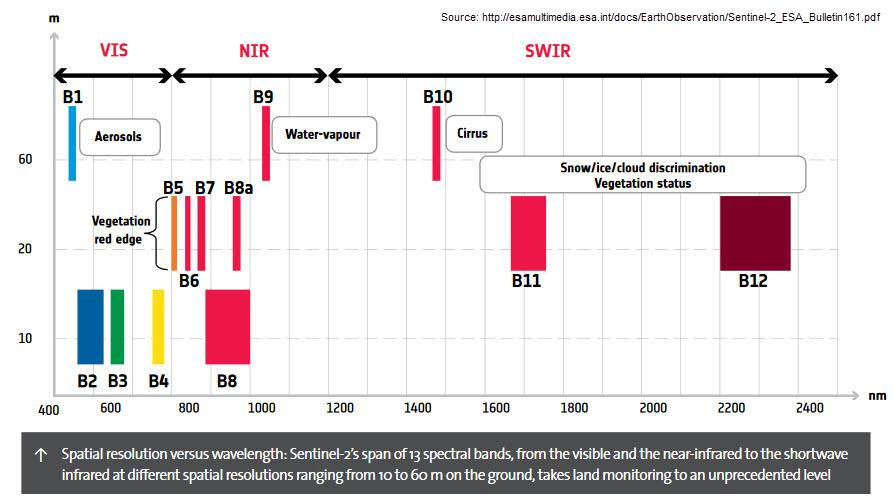

Vegetation absorbs much of the red light for photosynthesis and reflects a large amount of near-infrared radiation.

The Normalized Difference Vegetation Index (NDVI) is a simple remote-sensing metric used to measure and monitor the health, density, and growth of plant cover.

NDVI uses this difference: NDVI=NIR-RED/(NIR+RED)


For Sentinel-2: NDVI=B8-B4/(B8+B4)

Why Sentinel-2 and why not just MODIS?
The choice depends on what you want to predict.

If your goal is global historical environmental patterns, MODIS is convenient.

If your goal is predicting yield for individual agricultural fields, Sentinel-2 is usually more suitable because of its finer spatial resolution.




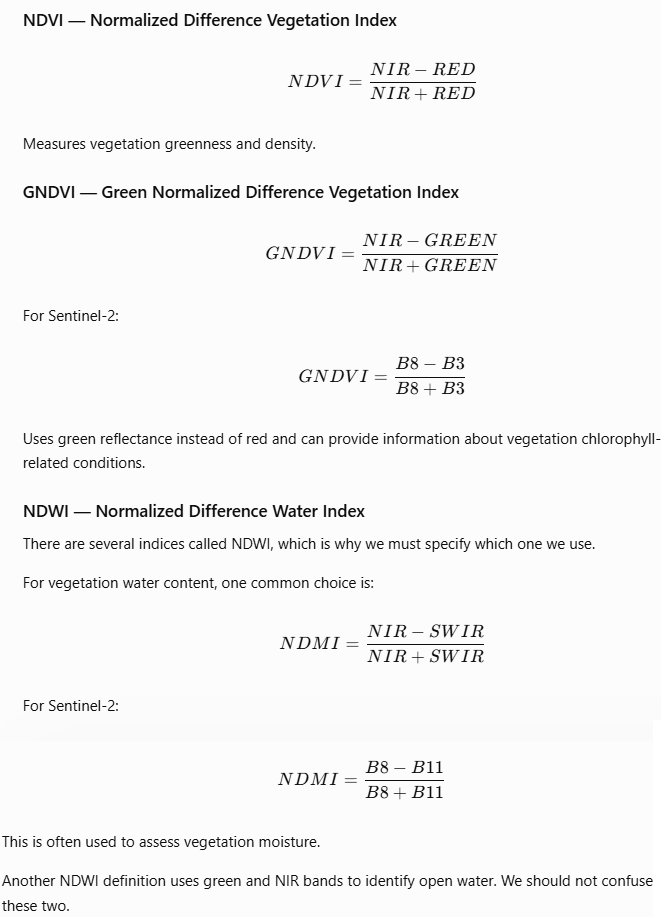

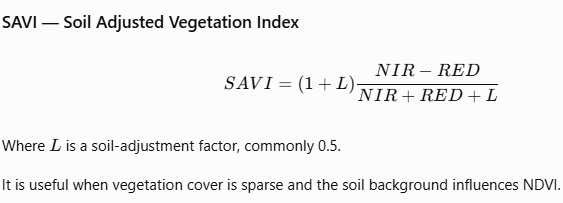

In [45]:
import ee

"""SummaryQA tells us how reliable the MODIS vegetation-index observation is.
SummaryQA, Meaning, What should we do?
0, Good data, Use
1, Marginal data, Use cautiously
2, Snow or ice, Usually exclude
3, Cloudy, Exclude
"""

modis = (
    ee.ImageCollection("MODIS/061/MOD13Q1")
    .filterDate(START_DATE, END_DATE)
    .select(["NDVI", "SummaryQA"])
)

def extract_modis(image):

    image = ee.Image(image)

    # Convert MODIS NDVI scale factor
    ndvi = image.select("NDVI").multiply(0.0001)

    # Preserve quality information
    quality = image.select("SummaryQA")

    combined = ndvi.rename("NDVI").addBands(
        quality.rename("SummaryQA")
    )

    sampled = combined.reduceRegions(
        collection=ee_points,
        reducer=ee.Reducer.first(),
        scale=250,
        tileScale=4
    )

    date = image.date().format("YYYY-MM-dd")

    return sampled.map(
        lambda feature: feature.set(
            "date", date
        )
    )


modis_table = ee.FeatureCollection(
    modis.map(extract_modis).flatten()
)

task = ee.batch.Export.table.toDrive(
    collection=modis_table,
    description="Global_MODIS_NDVI",
    folder="Agricultural_SI",
    fileNamePrefix="global_modis_ndvi",
    fileFormat="CSV"
)

task.start()

print("MODIS export started!")
print("Check task status:", task.status())

MODIS export started!
Check task status: {'state': 'READY', 'description': 'Global_MODIS_NDVI', 'priority': 100, 'creation_timestamp_ms': 1794757001081, 'update_timestamp_ms': 1794757001081, 'start_timestamp_ms': 0, 'task_type': 'EXPORT_FEATURES', 'id': 'KIGGSUSLMA6P473IZGGSVDWO', 'name': 'projects/nasahack-514813/operations/KIGGSUSLMA6P473IZGGSVDWO'}


# GPM IMERG — precipitation extraction

In [55]:
gpm = (
    ee.ImageCollection("NASA/GPM_L3/IMERG_V07")
    .filterDate(START_DATE, END_DATE)
    .select("precipitation")
)

def extract_gpm_day(image):

    image = ee.Image(image)

    # Average half-hourly estimates within each day
    daily = image.set(
        "day",
        image.date().format("YYYY-MM-dd")
    )

    return daily


# Aggregate to daily mean precipitation rate
start = ee.Date(START_DATE)
end = ee.Date(END_DATE)

number_of_days = end.difference(start, "day").toInt()

days = ee.List.sequence(
    0,
    number_of_days.subtract(1)
)

def daily_gpm(day):

    date = start.advance(day, "day")

    daily_collection = gpm.filterDate(
        date,
        date.advance(1, "day")
    )

    daily_image = daily_collection.mean()

    return daily_image.rename(
        "precipitation"
    ).set(
        "date",
        date.format("YYYY-MM-dd")
    )


daily_collection = ee.ImageCollection.fromImages(
    days.map(daily_gpm)
)

def sample_gpm(image):

    image = ee.Image(image)

    sampled = image.reduceRegions(
        collection=ee_points,
        reducer=ee.Reducer.first(),
        scale=11132,
        tileScale=4
    )

    return sampled.map(
        lambda f: f.set(
            "date",
            image.get("date")
        )
    )


gpm_table = ee.FeatureCollection(
    daily_collection.map(sample_gpm).flatten()
)

task = ee.batch.Export.table.toDrive(
    collection=gpm_table,
    description="Global_GPM_Precipitation",
    folder="Agricultural_SI",
    fileNamePrefix="global_gpm_daily",
    fileFormat="CSV"
)

task.start()

print("GPM extraction started!")
print(task.status())

GPM extraction started!
{'state': 'READY', 'description': 'Global_GPM_Precipitation', 'priority': 100, 'creation_timestamp_ms': 1794757759340, 'update_timestamp_ms': 1794757759340, 'start_timestamp_ms': 0, 'task_type': 'EXPORT_FEATURES', 'id': 'QTKGL6INCRE4OQUY7YGBHUVA', 'name': 'projects/nasahack-514813/operations/QTKGL6INCRE4OQUY7YGBHUVA'}


# ERA5-Land — historical climate and water conditions

In [47]:
era5 = (
    ee.ImageCollection("ECMWF/ERA5_LAND/DAILY_AGGR")
    .filterDate(START_DATE, END_DATE)
    .select([
        "temperature_2m",
        "total_precipitation_sum",
        "volumetric_soil_water_layer_1",
        "volumetric_soil_water_layer_2",
        "potential_evaporation_sum"
    ])
)

def sample_era5(image):

    image = ee.Image(image)

    sampled = image.reduceRegions(
        collection=ee_points,
        reducer=ee.Reducer.first(),
        scale=11132,
        tileScale=4
    )

    return sampled.map(
        lambda f: f.set(
            "date",
            image.date().format("YYYY-MM-dd")
        )
    )


era5_table = ee.FeatureCollection(
    era5.map(sample_era5).flatten()
)

task = ee.batch.Export.table.toDrive(
    collection=era5_table,
    description="Global_ERA5_Land",
    folder="Agricultural_SI",
    fileNamePrefix="global_era5_land",
    fileFormat="CSV"
)

task.start()

print("ERA5-Land extraction started!")
print(task.status())

ERA5-Land extraction started!
{'state': 'READY', 'description': 'Global_ERA5_Land', 'priority': 100, 'creation_timestamp_ms': 1794757050873, 'update_timestamp_ms': 1794757050873, 'start_timestamp_ms': 0, 'task_type': 'EXPORT_FEATURES', 'id': 'HPEOOL57FNFTVLTATAP5GSYM', 'name': 'projects/nasahack-514813/operations/HPEOOL57FNFTVLTATAP5GSYM'}


# SoilGrids — soil properties

In [48]:
soil_points = locations[
    [
        "location_id",
        "latitude",
        "longitude",
        "country"
    ]
].copy()

soil_points.to_csv(
    ROOT / "data/processed/soil_sampling_points.csv",
    index=False
)

print("Soil sampling coordinates prepared!")

Soil sampling coordinates prepared!


In [56]:
import rasterio

def sample_raster(raster_path, locations):

    results = []

    with rasterio.open(raster_path) as src:

        for _, point in locations.iterrows():

            x, y = rasterio.warp.transform(
                "EPSG:4326",
                src.crs,
                [point["longitude"]],
                [point["latitude"]]
            )

            row, col = src.index(x[0], y[0])

            if (
                row < 0 or col < 0
                or row >= src.height
                or col >= src.width
            ):
                value = None

            else:
                value = src.read(1)[row, col]

                if src.nodata is not None and value == src.nodata:
                    value = None
                else:
                    value = float(value)

            results.append({
                "location_id": point["location_id"],
                "value": value
            })

    return pd.DataFrame(results)

In [57]:
def add_ndvi(image):

    ndvi = image.normalizedDifference(
        ["B8", "B4"]
    ).rename("NDVI")

    return image.addBands(ndvi)

In [58]:
def calculate_temperature_anomaly(df):

    df = df.copy()

    # Compare each observation with its
    # location-specific monthly climatology

    df["month"] = df["date"].dt.month

    df["temperature_baseline"] = (
        df.groupby(
            ["location_id", "month"]
        )["T2M"].transform("mean")
    )

    df["temperature_anomaly"] = (
        df["T2M"] - df["temperature_baseline"]
    )

    return df


def calculate_precipitation_anomaly(df):

    df = df.copy()

    df["month"] = df["date"].dt.month

    df["precipitation_baseline"] = (
        df.groupby(
            ["location_id", "month"]
        )["PRECTOTCORR"].transform("mean")
    )

    df["precipitation_anomaly"] = (
        df["PRECTOTCORR"]
        - df["precipitation_baseline"]
    )

    return df


def calculate_frost_indicator(df):

    df = df.copy()

    # Approximate daily frost indicator
    # based on minimum air temperature.

    df["frost_day"] = (
        df["T2M_MIN"] < 0
    ).astype("Int64")

    return df


def calculate_all_indicators(df):

    df = df.copy()

    df["date"] = pd.to_datetime(df["date"])

    df = calculate_temperature_anomaly(df)

    df = calculate_precipitation_anomaly(df)

    df = calculate_frost_indicator(df)

    return df


if not power_data.empty:

    power_features = calculate_all_indicators(
        power_data
    )

    power_features.to_csv(
        ROOT / "data/processed/weather_features.csv",
        index=False
    )

    print(power_features.head())

        date    T2M  T2M_MAX  T2M_MIN  PRECTOTCORR   RH2M  ALLSKY_SFC_SW_DWN  \
0 2020-01-01  28.60    31.86    25.13         0.01  62.79              19.44   
1 2020-01-02  28.98    33.00    25.90         0.12  61.47              20.53   
2 2020-01-03  28.76    32.32    25.99         0.01  64.03              20.15   
3 2020-01-04  28.99    33.78    26.25         0.02  66.39              18.84   
4 2020-01-05  30.03    34.18    26.25         0.00  57.85              20.23   

  location_id   latitude  longitude   country     field_name  month  \
0  field_0001  13.100466 -87.253438  Honduras  Cropland_0001      1   
1  field_0001  13.100466 -87.253438  Honduras  Cropland_0001      1   
2  field_0001  13.100466 -87.253438  Honduras  Cropland_0001      1   
3  field_0001  13.100466 -87.253438  Honduras  Cropland_0001      1   
4  field_0001  13.100466 -87.253438  Honduras  Cropland_0001      1   

   temperature_baseline  temperature_anomaly  precipitation_baseline  \
0             28.550

In [59]:
def monthly_aggregation(df):

    df = df.copy()

    df["date"] = pd.to_datetime(df["date"])

    df["month"] = (
        df["date"].dt.to_period("M").dt.to_timestamp()
    )

    aggregations = {
        "T2M": "mean",
        "T2M_MAX": "max",
        "T2M_MIN": "min",
        "PRECTOTCORR": "sum",
        "RH2M": "mean",
        "ALLSKY_SFC_SW_DWN": "mean",
        "temperature_anomaly": "mean",
        "precipitation_anomaly": "sum",
        "frost_day": "sum"
    }

    aggregations = {
        col: method
        for col, method in aggregations.items()
        if col in df.columns
    }

    result = (
        df.groupby(
            [
                "location_id",
                "latitude",
                "longitude",
                "country",
                "month"
            ],
            dropna=False
        )
        .agg(aggregations)
        .reset_index()
    )

    return result


if not power_data.empty:

    monthly_weather = monthly_aggregation(
        power_features
    )

    monthly_weather.to_csv(
        ROOT / "data/processed/monthly_weather.csv",
        index=False
    )

    print(monthly_weather.head())

  location_id   latitude  longitude   country      month        T2M  T2M_MAX  \
0  field_0001  13.100466 -87.253438  Honduras 2020-01-01  29.173548    35.03   
1  field_0001  13.100466 -87.253438  Honduras 2020-02-01  30.125862    36.66   
2  field_0001  13.100466 -87.253438  Honduras 2020-03-01  30.859355    37.15   
3  field_0001  13.100466 -87.253438  Honduras 2020-04-01  30.924333    38.06   
4  field_0001  13.100466 -87.253438  Honduras 2020-05-01  29.987742    36.63   

   T2M_MIN  PRECTOTCORR       RH2M  ALLSKY_SFC_SW_DWN  temperature_anomaly  \
0    24.89         1.58  60.708387          20.230323             0.622903   
1    25.06         1.01  56.499310          22.776207             0.902215   
2    25.05         0.37  55.007742          25.192581             0.698978   
3    27.07         6.15  62.123667          22.242667             0.609389   
4    24.60       190.85  70.348387          18.231935             0.034301   

   precipitation_anomaly  frost_day  
0           

In [60]:
def build_final_dataset(
    locations,
    weather,
    soil=None,
    vegetation=None,
    soil_moisture=None,
    precipitation=None
):

    final = weather.copy()

    # Attach static geographic information
    final = final.merge(
        locations[
            [
                "location_id",
                "field_name"
            ]
        ],
        on="location_id",
        how="left"
    )

    # Add static soil characteristics
    if soil is not None:

        final = final.merge(
            soil,
            on="location_id",
            how="left"
        )

    # Add vegetation observations
    if vegetation is not None:

        final = final.merge(
            vegetation,
            on=["location_id", "month"],
            how="left"
        )

    # Add soil moisture observations
    if soil_moisture is not None:

        final = final.merge(
            soil_moisture,
            on=["location_id", "month"],
            how="left"
        )

    # Add precipitation observations
    if precipitation is not None:

        final = final.merge(
            precipitation,
            on=["location_id", "month"],
            how="left"
        )

    return final


# Initially, use the weather data
final_dataset = build_final_dataset(
    locations=locations,
    weather=monthly_weather
)

final_dataset.to_csv(
    ROOT / "data/final/agricultural_features.csv",
    index=False
)

print("Final dataset created!")
print("Rows:", len(final_dataset))
print("Columns:", len(final_dataset.columns))

display(final_dataset.head(10))

Final dataset created!
Rows: 7200
Columns: 15


,location_id,latitude,longitude,country,month,T2M,T2M_MAX,T2M_MIN,PRECTOTCORR,RH2M,ALLSKY_SFC_SW_DWN,temperature_anomaly,precipitation_anomaly,frost_day,field_name
0,field_0001,13.100466,-87.253438,Honduras,2020-01-01,29.173548,35.03,24.89,1.58,60.708387,20.230323,0.622903,-11.240000,0,Cropland_0001
1,field_0001,13.100466,-87.253438,Honduras,2020-02-01,30.125862,36.66,25.06,1.01,56.499310,22.776207,0.902215,-9.032529,0,Cropland_0001
2,field_0001,13.100466,-87.253438,Honduras,2020-03-01,30.859355,37.15,25.05,0.37,55.007742,25.192581,0.698978,-32.231667,0,Cropland_0001
3,field_0001,13.100466,-87.253438,Honduras,2020-04-01,30.924333,38.06,27.07,6.15,62.123667,22.242667,0.609389,-44.618333,0,Cropland_0001
4,field_0001,13.100466,-87.253438,Honduras,2020-05-01,29.987742,36.63,24.60,190.85,70.348387,18.231935,0.034301,20.100000,0,Cropland_0001
5,field_0001,13.100466,-87.253438,Honduras,2020-06-01,28.375333,32.97,24.80,335.66,78.994000,18.954667,-0.158833,4.310000,0,Cropland_0001
6,field_0001,13.100466,-87.253438,Honduras,2020-07-01,29.310968,36.33,25.15,86.92,71.991290,22.553548,0.020269,-64.975000,0,Cropland_0001
7,field_0001,13.100466,-87.253438,Honduras,2020-08-01,29.154839,35.55,25.23,178.13,74.511290,20.763548,-0.154086,-40.693333,0,Cropland_0001
8,field_0001,13.100466,-87.253438,Honduras,2020-09-01,28.015667,32.28,25.70,382.53,81.208333,21.720667,-0.562722,67.741667,0,Cropland_0001
9,field_0001,13.100466,-87.253438,Honduras,2020-10-01,27.517097,31.41,24.52,406.59,81.553548,19.114839,-0.493978,137.146667,0,Cropland_0001


In [61]:
def create_quality_report(df):

    report = pd.DataFrame({
        "column": df.columns,
        "missing_values": [
            df[col].isna().sum()
            for col in df.columns
        ],
        "missing_percentage": [
            df[col].isna().mean() * 100
            for col in df.columns
        ],
        "data_type": [
            str(df[col].dtype)
            for col in df.columns
        ]
    })

    return report


quality_report = create_quality_report(
    final_dataset
)

quality_report.to_csv(
    ROOT / "data/final/data_quality_report.csv",
    index=False
)

display(quality_report)

,column,missing_values,missing_percentage,data_type
0,location_id,0,0.0,object
1,latitude,0,0.0,float64
2,longitude,0,0.0,float64
3,country,0,0.0,object
4,month,0,0.0,datetime64[ns]
5,T2M,0,0.0,float64
6,T2M_MAX,0,0.0,float64
7,T2M_MIN,0,0.0,float64
8,PRECTOTCORR,0,0.0,float64
9,RH2M,0,0.0,float64


In [62]:
import folium

m = folium.Map(location=[48.3794, 31.1656], zoom_start=4)

# Add a marker for a specific country capital
folium.Marker(
    location=[50.4501, 30.5234],
    popup="Kyiv, Ukraine"
).add_to(m)

m.save("map.html")

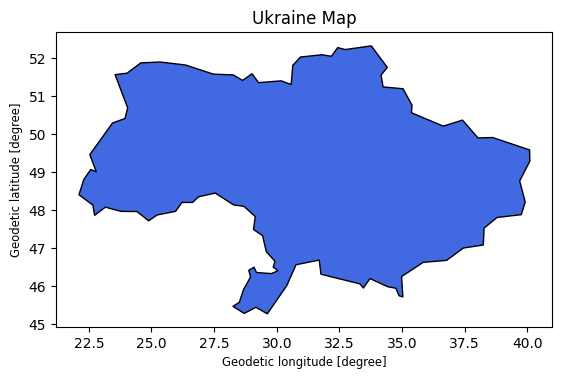

In [64]:
import geopandas as gpd
import matplotlib.pyplot as plt

# Load world boundaries from a Natural Earth URL
url = "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_110m_admin_0_countries.geojson"
world = gpd.read_file(url)

# Filter and plot a specific country
ukraine = world[world["NAME"] == "Ukraine"]
ukraine.plot(color="royalblue", edgecolor="black")
plt.title("Ukraine Map")
plt.show()

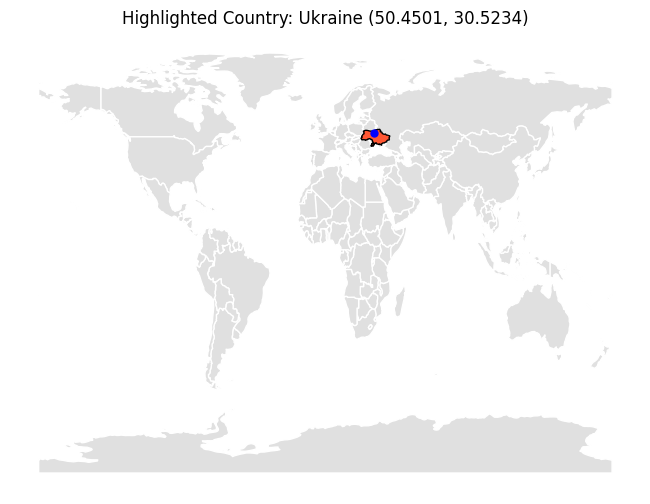

In [67]:
import geopandas as gpd
from shapely.geometry import Point
import matplotlib.pyplot as plt

# 1. Load the world map boundaries
url = "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_110m_admin_0_countries.geojson"
world = gpd.read_file(url)

# 2. Define your coordinates (Longitude, Latitude)
# Note: Shapely uses (Longitude, Latitude) order!
lat, lon = 50.4501, 30.5234  # Example: Kyiv, Ukraine
point = Point(lon, lat)

# 3. Find which country polygon contains the point
highlighted_country = world[world.contains(point)]

# 4. Plot the world map and layer the highlighted country on top
fig, ax = plt.subplots(figsize=(12, 6))

# Base layer: all countries in light gray
world.plot(ax=ax, color="#e0e0e0", edgecolor="white")

# Highlight layer: matched country in bright color
if not highlighted_country.empty:
    highlighted_country.plot(ax=ax, color="#ff5733", edgecolor="black")
    country_name = highlighted_country.iloc[0]["NAME"]
    plt.title(f"Highlighted Country: {country_name} ({lat}, {lon})")
else:
    plt.title("Coordinates did not fall inside any country polygon")

# Optional: Plot a dot at the exact coordinate
ax.plot(lon, lat, marker="o", color="blue", markersize=5)

plt.axis("off")
plt.show()
